# 02 — Exploratory Data Analysis

Work load, digital habits and wellbeing versus actual productivity.


In [15]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted')

df = pd.read_csv(ROOT / 'data' / 'cleaned.csv')
print(df.shape)
df.head(3)


(29961, 19)


,age,gender,job_type,daily_social_media_time,social_platform_preference,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,uses_focus_apps,has_digital_wellbeing_enabled,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
0,30,Male,Finance,2.00,Telegram,32,8.00,6,8.00,5,8.00,1,3,1,1,1,0,20,6
1,24,Female,Health,2.00,Instagram,19,12.00,7,4.00,6,6.00,0,2,0,0,2,8,8,5
2,52,Female,Student,4.00,Telegram,80,5.00,5,7.00,3,8.00,2,3,1,0,1,0,13,8


## 1. Target overview


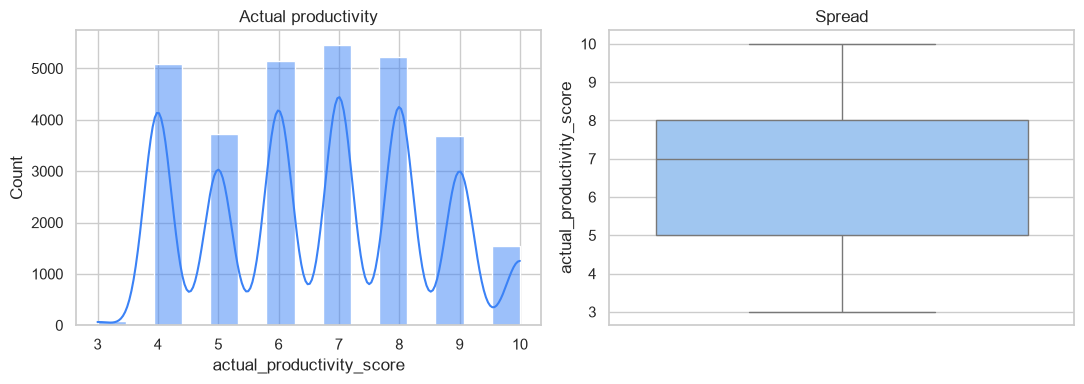

count   29961.00
mean        6.63
std         1.80
min         3.00
25%         5.00
50%         7.00
75%         8.00
max        10.00
Name: actual_productivity_score, dtype: float64


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['actual_productivity_score'], bins=15, kde=True, ax=ax[0], color='#3b82f6')
ax[0].set_title('Actual productivity')
sns.boxplot(y=df['actual_productivity_score'], ax=ax[1], color='#93c5fd')
ax[1].set_title('Spread')
plt.tight_layout()
plt.show()
print(df['actual_productivity_score'].describe())


## 2. Correlation with the target


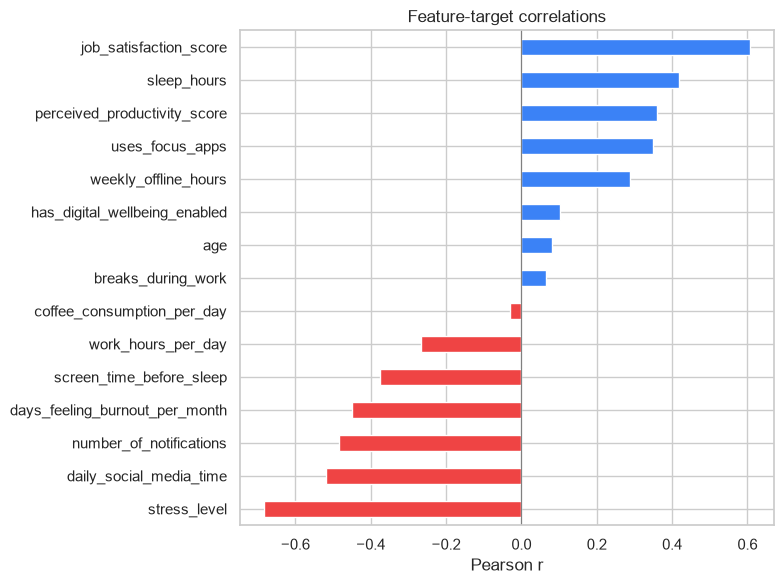

stress_level                     -0.68
daily_social_media_time          -0.52
number_of_notifications          -0.48
days_feeling_burnout_per_month   -0.45
screen_time_before_sleep         -0.38
work_hours_per_day               -0.27
coffee_consumption_per_day       -0.03
breaks_during_work                0.07
age                               0.08
has_digital_wellbeing_enabled     0.10
weekly_offline_hours              0.29
uses_focus_apps                   0.35
perceived_productivity_score      0.36
sleep_hours                       0.42
job_satisfaction_score            0.61
Name: actual_productivity_score, dtype: float64


In [17]:
num = df.select_dtypes(include='number')
corr = num.corr()['actual_productivity_score'].drop('actual_productivity_score').sort_values()
plt.figure(figsize=(8, 6))
corr.plot(kind='barh', color=['#ef4444' if v < 0 else '#3b82f6' for v in corr.values])
plt.axvline(0, color='grey', lw=0.8)
plt.title('Feature-target correlations')
plt.xlabel('Pearson r')
plt.tight_layout()
plt.show()
print(corr.round(3))


## 3. Correlation heatmap


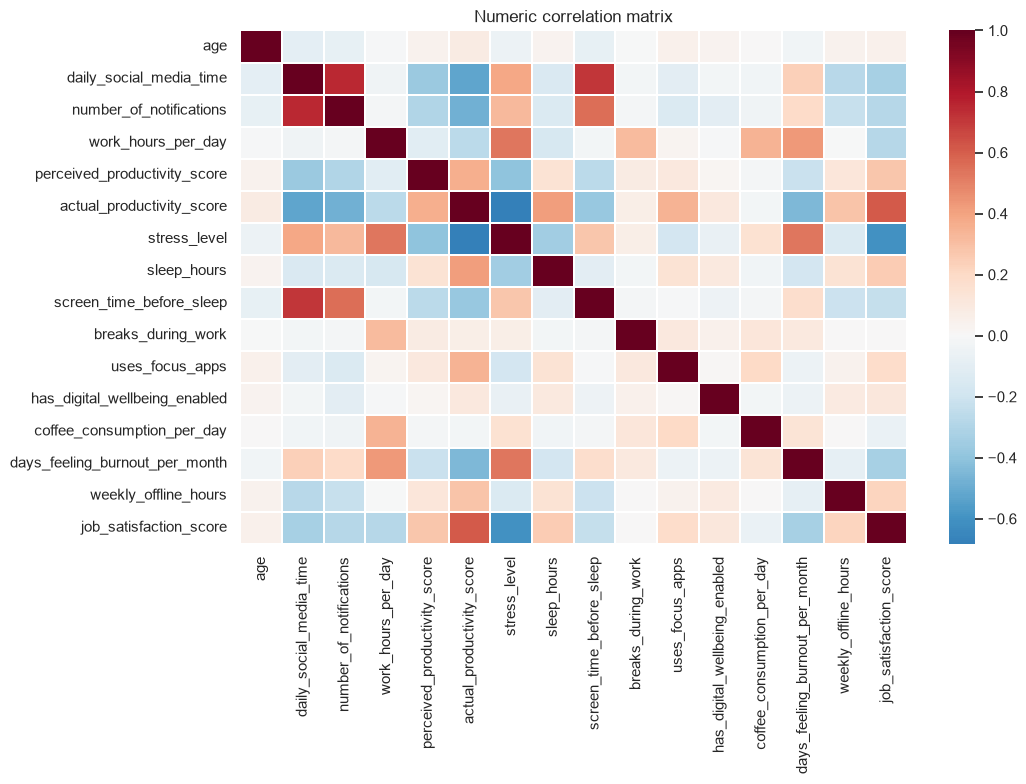

In [18]:
plt.figure(figsize=(11, 8))
sns.heatmap(num.corr(), cmap='RdBu_r', center=0, linewidths=0.3)
plt.title('Numeric correlation matrix')
plt.tight_layout()
plt.show()


## 4. Productivity by job type


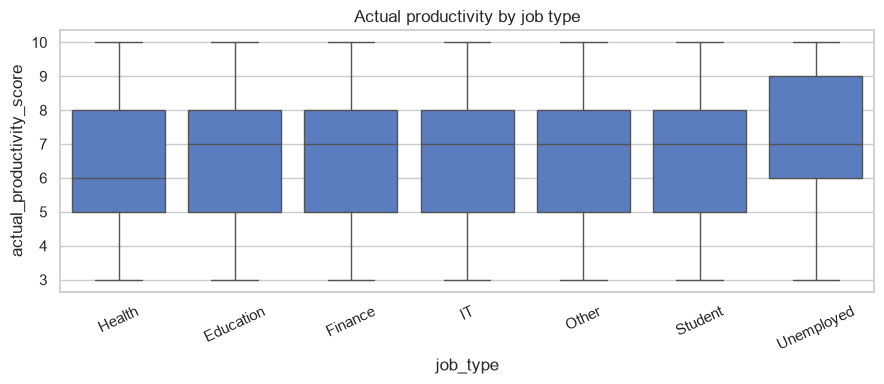

,count,mean,std,min,25%,50%,75%,max
job_type,,,,,,,,
Education,4068.00,6.68,1.78,3.00,5.00,7.00,8.00,10.00
Finance,4355.00,6.56,1.79,3.00,5.00,7.00,8.00,10.00
Health,4986.00,6.44,1.82,3.00,5.00,6.00,8.00,10.00
IT,5605.00,6.58,1.81,3.00,5.00,7.00,8.00,10.00
Other,623.00,6.61,1.77,3.00,5.00,7.00,8.00,10.00
Student,6545.00,6.50,1.76,3.00,5.00,7.00,8.00,10.00
Unemployed,3779.00,7.26,1.72,3.00,6.00,7.00,9.00,10.00


In [19]:
plt.figure(figsize=(9, 4))
order = df.groupby('job_type')['actual_productivity_score'].median().sort_values().index
sns.boxplot(data=df, x='job_type', y='actual_productivity_score', order=order)
plt.xticks(rotation=25)
plt.title('Actual productivity by job type')
plt.tight_layout()
plt.show()
df.groupby('job_type')['actual_productivity_score'].describe().round(2)


## 5. Productivity by platform


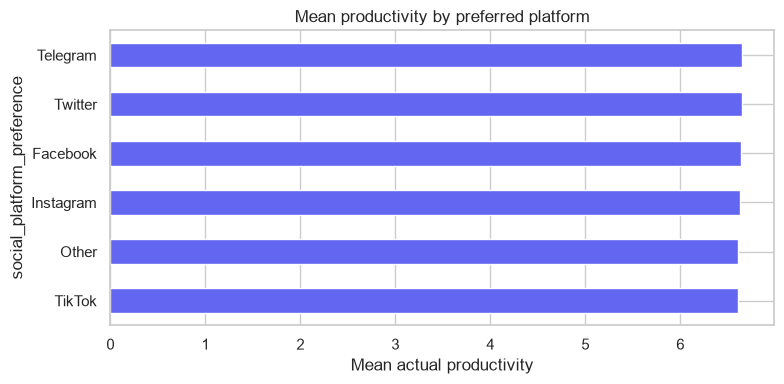

social_platform_preference
TikTok      6.61
Other       6.61
Instagram   6.63
Facebook    6.64
Twitter     6.65
Telegram    6.65
Name: actual_productivity_score, dtype: float64


In [20]:
plat = df.groupby('social_platform_preference')['actual_productivity_score'].mean().sort_values()
plt.figure(figsize=(8, 4))
plat.plot(kind='barh', color='#6366f1')
plt.xlabel('Mean actual productivity')
plt.title('Mean productivity by preferred platform')
plt.tight_layout()
plt.show()
print(plat.round(2))


## 6. Social media time vs productivity


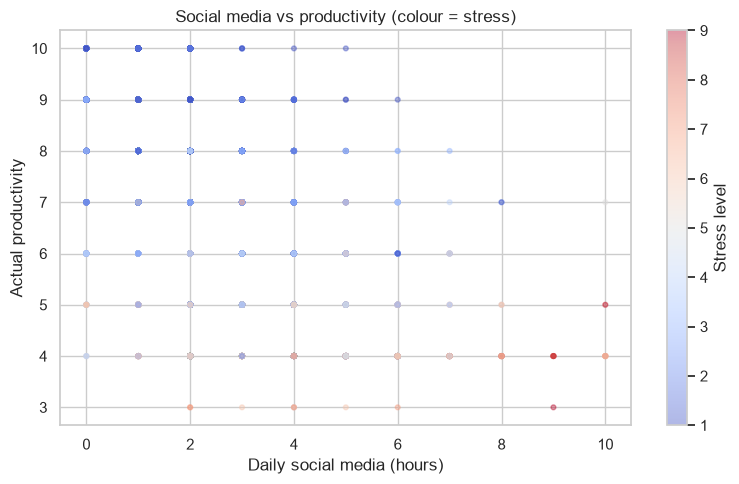

In [21]:
sample = df.sample(min(4000, len(df)), random_state=1)
plt.figure(figsize=(8, 5))
sc = plt.scatter(sample['daily_social_media_time'], sample['actual_productivity_score'],
                 c=sample['stress_level'], cmap='coolwarm', alpha=0.4, s=12)
plt.colorbar(sc, label='Stress level')
plt.xlabel('Daily social media (hours)')
plt.ylabel('Actual productivity')
plt.title('Social media vs productivity (colour = stress)')
plt.tight_layout()
plt.show()


## 7. Sleep, burnout, offline hours


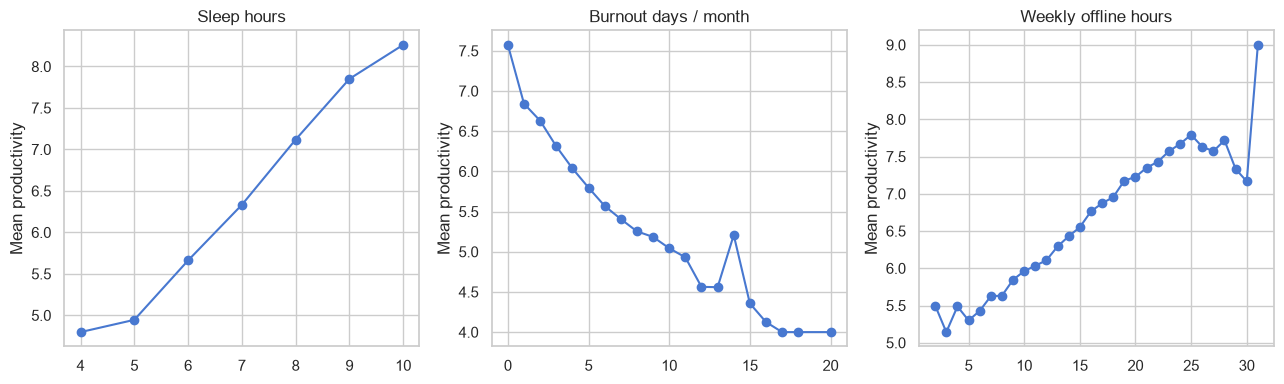

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in zip(axes,
    ['sleep_hours', 'days_feeling_burnout_per_month', 'weekly_offline_hours'],
    ['Sleep hours', 'Burnout days / month', 'Weekly offline hours']):
    tmp = df.groupby(col)['actual_productivity_score'].mean()
    ax.plot(tmp.index, tmp.values, marker='o')
    ax.set_title(title)
    ax.set_ylabel('Mean productivity')
plt.tight_layout()
plt.show()


## 8. Stress x work hours


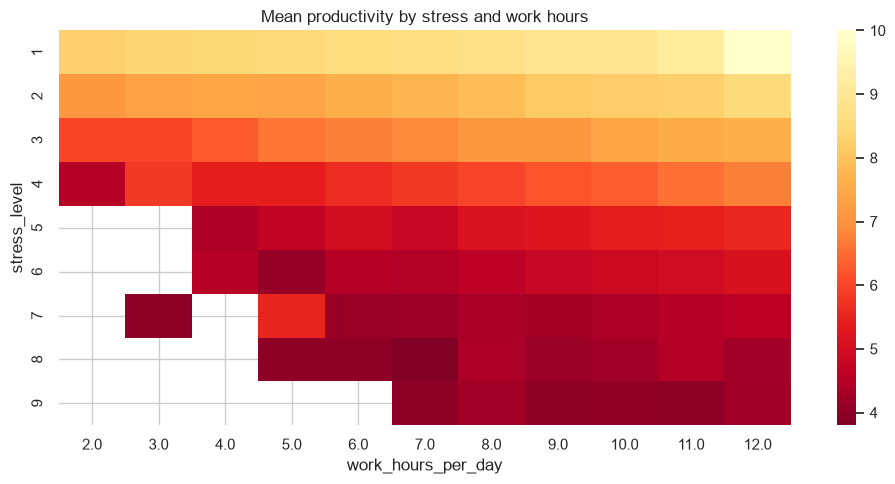

In [23]:
pivot = df.pivot_table(values='actual_productivity_score', index='stress_level',
                       columns='work_hours_per_day', aggfunc='mean')
plt.figure(figsize=(10, 5))
sns.heatmap(pivot, cmap='YlOrRd_r')
plt.title('Mean productivity by stress and work hours')
plt.tight_layout()
plt.show()


## 9. Focus apps and digital wellbeing


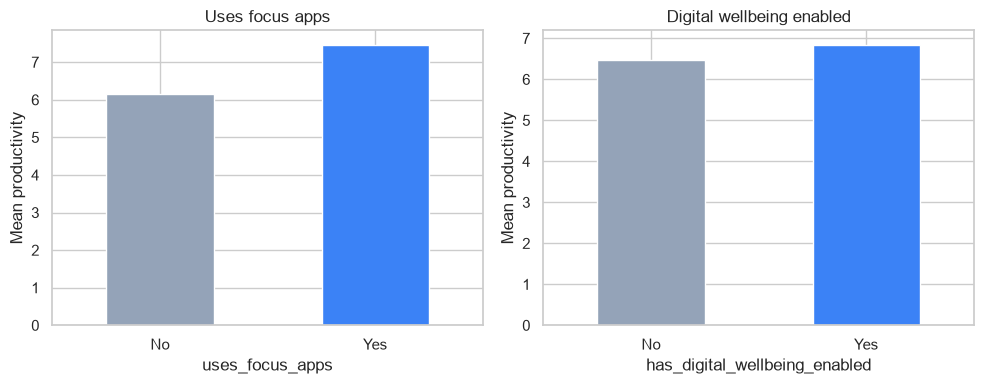

uses_focus_apps
                 mean  median  count
uses_focus_apps                     
0                6.16    6.00  19164
1                7.47    8.00  10797

has_digital_wellbeing_enabled
                               mean  median  count
has_digital_wellbeing_enabled                     
0                              6.48    6.00  17344
1                              6.85    7.00  12617



In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, title in zip(axes,
    ['uses_focus_apps', 'has_digital_wellbeing_enabled'],
    ['Uses focus apps', 'Digital wellbeing enabled']):
    tmp = df.groupby(col)['actual_productivity_score'].mean()
    tmp.index = tmp.index.map({0: 'No', 1: 'Yes', False: 'No', True: 'Yes'})
    tmp.plot(kind='bar', ax=ax, color=['#94a3b8', '#3b82f6'], rot=0)
    ax.set_title(title)
    ax.set_ylabel('Mean productivity')
plt.tight_layout()
plt.show()
for col in ['uses_focus_apps', 'has_digital_wellbeing_enabled']:
    print(col)
    print(df.groupby(col)['actual_productivity_score'].agg(['mean', 'median', 'count']).round(2))
    print()


## 10. Perceived vs actual


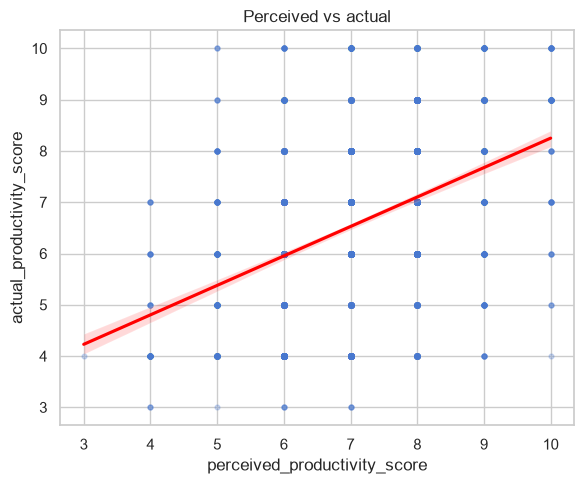

Correlation: 0.359


In [25]:
sample = df.sample(min(3000, len(df)), random_state=2)
plt.figure(figsize=(6, 5))
sns.regplot(data=sample, x='perceived_productivity_score', y='actual_productivity_score',
            scatter_kws={'alpha': 0.25, 's': 12}, line_kws={'color': 'red'})
plt.title('Perceived vs actual')
plt.tight_layout()
plt.show()
print('Correlation:', round(df[['perceived_productivity_score','actual_productivity_score']].corr().iloc[0,1], 3))


## 11. Notifications and screen-before-sleep


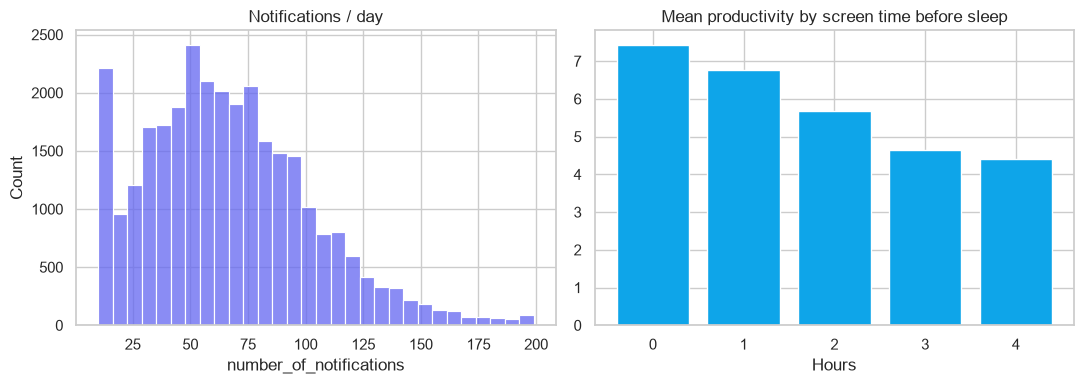

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['number_of_notifications'], bins=30, ax=axes[0], color='#6366f1')
axes[0].set_title('Notifications / day')
sc = df.groupby('screen_time_before_sleep')['actual_productivity_score'].mean()
axes[1].bar(sc.index.astype(str), sc.values, color='#0ea5e9')
axes[1].set_title('Mean productivity by screen time before sleep')
axes[1].set_xlabel('Hours')
plt.tight_layout()
plt.show()


## 12. Coffee and breaks


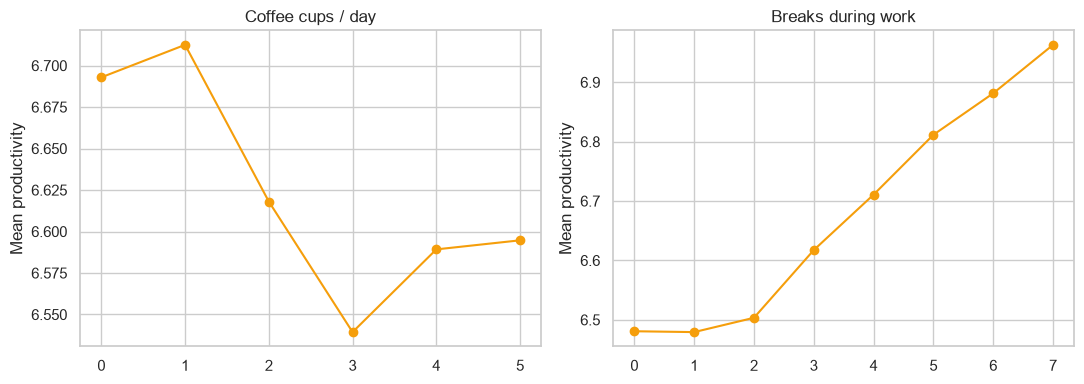

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes,
    ['coffee_consumption_per_day', 'breaks_during_work'],
    ['Coffee cups / day', 'Breaks during work']):
    tmp = df.groupby(col)['actual_productivity_score'].mean()
    ax.plot(tmp.index, tmp.values, marker='o', color='#f59e0b')
    ax.set_title(title)
    ax.set_ylabel('Mean productivity')
plt.tight_layout()
plt.show()


## 13. Job satisfaction vs productivity


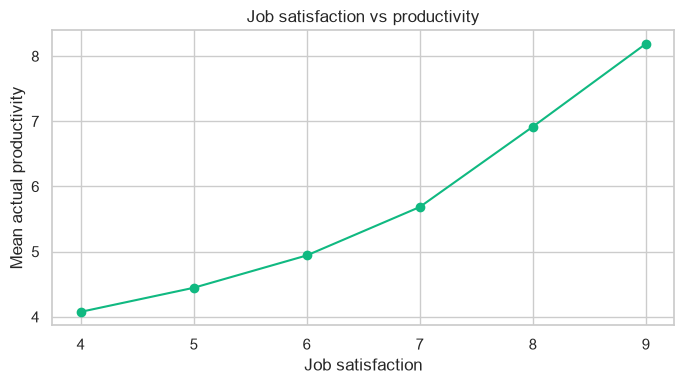

In [28]:
tmp = df.groupby('job_satisfaction_score')['actual_productivity_score'].mean()
plt.figure(figsize=(7, 4))
plt.plot(tmp.index, tmp.values, marker='o', color='#10b981')
plt.xlabel('Job satisfaction')
plt.ylabel('Mean actual productivity')
plt.title('Job satisfaction vs productivity')
plt.tight_layout()
plt.show()


## Takeaways

- Higher burnout and stress tend to align with lower productivity.
- Sleep and offline hours show a milder positive link.
- Perceived productivity tracks actual scores but is not identical.
- Job type and platform differences exist; Other captures unlisted form options.
